days_to_event Survival Modeling Problem

By: Maria Gonzalez

Date: 9.26.26-10.31.26

This notebook documents the days_to_event Survival Modeling Problem step for the Break Through Tech Healthcare 1E project.

Notes for running this notebook:

This notebook can be run independently from the notebooks/ folder from the Github since the Cox model built here is independent from other tasks.

In [5]:
#!pip install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=b03a4443d004d70de6b6c546d15c21e582cb50b23b75cf84972fc13259b0609f
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


In [8]:
import argparse
import warnings
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index, k_fold_cross_validation
from sklearn.model_selection import train_test_split

Load data

Load the CSV, drop rows missing the time or event, and keep only positive durations (Cox requires them).

In [11]:
from google.colab import drive
drive.mount("/content/drive")

DURATION_COL = "days_to_event"
EVENT_COL = "event_adverse"
DROP_COLS = []
RANDOM_STATE = 42
TEST_SIZE = 0.2

DATA_PATH = "/content/drive/MyDrive/Healthcare-1E-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/data/processed/engineered_features.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)

# Make sure the columns the Cox model needs are present
missing = [c for c in (DURATION_COL, EVENT_COL) if c not in df.columns]
print("Missing columns (should be []):", missing)

df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
df = df.dropna(subset=[DURATION_COL, EVENT_COL])
df = df[df[DURATION_COL] > 0].copy()
df[EVENT_COL] = df[EVENT_COL].astype(int)

print(f"Rows: {len(df)} | Event rate: {df[EVENT_COL].mean():.3f} | "
      f"Median follow-up: {df[DURATION_COL].median():.0f} days")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(494862, 49)
Missing columns (should be []): []
Rows: 494013 | Event rate: 0.141 | Median follow-up: 434 days


,BMI_TCR,INIT_CPRA,INIT_AGE,event_adverse,functional_percent,dialysis_duration_days,cpra_missing,age_x_functional,ON_DIALYSIS_Y,GENDER_M,...,functional_scale_adult_karnofsky,functional_scale_not_applicable,functional_scale_other/unresolved,functional_scale_pediatric_lansky,functional_scale_unknown,policy_era_post_2021,bmi_category_normal,bmi_category_overweight,bmi_category_obese,days_to_event
0,0.482147,-0.394604,0.077082,1,0.185956,0.156586,0,0.190308,True,False,...,True,False,False,False,False,False,False,False,True,287.0
1,0.208879,-0.394604,0.282547,0,-0.507535,0.359177,0,-0.051554,True,True,...,True,False,False,False,False,False,False,False,True,2322.0
2,0.691824,-0.394604,-0.333849,1,-0.507535,-0.634175,0,-0.527720,False,False,...,True,False,False,False,False,False,False,False,True,604.0
3,-1.516663,-0.394604,0.624989,1,0.879447,-0.140766,0,1.135081,True,True,...,True,False,False,False,False,False,True,False,False,909.0
4,-0.949502,-0.394604,0.624989,1,-0.507535,-0.208297,0,0.212982,True,True,...,True,False,False,False,False,False,True,False,False,231.0


Train

Stratified on event_adverse so both sets have the same proportion of events and censored patients.

In [12]:
train, test = train_test_split(
    df, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df[EVENT_COL]
)
print(train.shape, test.shape)

(395210, 49) (98803, 49)


Preprocessing

Impute missing values, standardize numeric columns, and one-hot encode categoricals. Every statistic (median, mean, std, mode) is computed on the training set only to avoid leakage.

In [13]:
y_cols = [DURATION_COL, EVENT_COL]
feat_cols = [c for c in train.columns if c not in y_cols]

train_df, test_df = train.copy(), test.copy()

#booleans -> 0/1 floats
train_df[feat_cols] = train_df[feat_cols].astype(float)
test_df[feat_cols] = test_df[feat_cols].astype(float)

# fill missing vals with train medians
print(train_df[feat_cols].isna().sum().loc[lambda s: s > 0])
med = train_df[feat_cols].median()
train_df[feat_cols] = train_df[feat_cols].fillna(med)
test_df[feat_cols] = test_df[feat_cols].fillna(med)

#remove zero-variance columns
keep = [c for c in feat_cols if train_df[c].std() > 0]
train_df = train_df[keep + y_cols]
test_df = test_df[keep + y_cols]
print(train_df.shape, test_df.shape)

BMI_TCR        1256
INIT_CPRA    114121
dtype: int64
(395210, 49) (98803, 49)


Tune the penalizer

A small L2 penalty stabilizes the fit when features are correlated so I chose the value with the best 5-fold cross-validated C-index on the training set.

In [27]:
#removing problematic features
drop_cols = ["ABO_A2B", "INIT_STAT_4020", "INIT_STAT_4060"]

tune_df = train_df.drop(columns=drop_cols).sample(
    50000, random_state=RANDOM_STATE
)

best_p, best_score = None, -np.inf

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    for p in (1.0, 10.0, 100.0, 1000.0):
        try:
            scores = k_fold_cross_validation(
                CoxPHFitter(penalizer=p),
                tune_df,
                duration_col=DURATION_COL,
                event_col=EVENT_COL,
                k=5,
                scoring_method="concordance_index",
            )

            m = np.mean(scores)
            print(f"penalizer={p:<8} CV C-index = {m:.4f}")

            if m > best_score:
                best_p, best_score = p, m

        except Exception as e:
            print(f"penalizer={p:<8} failed: {type(e).__name__}: {e}")

print("Selected:", best_p, best_score)

penalizer=1.0      CV C-index = 0.6690
penalizer=10.0     CV C-index = 0.6650
penalizer=100.0    CV C-index = 0.6647
penalizer=1000.0   CV C-index = 0.6653
Selected: 1.0 0.6690145028968832


Fit the final model CoxPHFitter on the full training set with the selected penalizer.

In [28]:
train_df = train_df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)
cph = CoxPHFitter(penalizer=best_p)
cph.fit(train_df, duration_col=DURATION_COL, event_col=EVENT_COL)

<lifelines.CoxPHFitter: fitted with 395210 total observations, 339530 right-censored observations>

Evaluate performance with C-index

In [29]:
def c_index(model, df):
    risk = model.predict_partial_hazard(df)
    return concordance_index(df[DURATION_COL], -risk, df[EVENT_COL])

print(f"Train C-index: {c_index(cph, train_df):.4f}")
print(f"Test C-index : {c_index(cph, test_df):.4f}")

Train C-index: 0.6745
Test C-index : 0.6796


Interpret the model
exp(coef) is the hazard ratio: above 1 means higher risk of the adverse event, below 1 means lower risk.

In [30]:
summ = cph.summary[["coef", "exp(coef)", "p"]].sort_values("p")
summ.head(10)

,coef,exp(coef),p
covariate,,,
INIT_AGE,0.047653,1.048807,2.266923e-217
functional_percent,-0.036806,0.963863,8.478244e-132
dialysis_duration_days,0.021548,1.021782,4.393977e-45
age_x_functional,0.019299,1.019487,2.302752e-37
REGION_5,-0.040191,0.960606,5.059308e-24
ETHCAT_5,-0.037980,0.962732,1.381145e-11
ETHCAT_4,-0.021747,0.978487,5.972310e-09
INIT_STAT_4099,-0.018991,0.981188,6.005967e-09
REGION_4,0.027301,1.027677,6.892674e-09


Check the proportional hazards assumption

Cox assumes each feature's effect is constant over time. Warnings here are common for a baseline

In [31]:
cph.check_assumptions(train_df, p_value_threshold=0.01, show_plots=False)

The ``p_value_threshold`` is set at 0.01. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'BMI_TCR' failed the non-proportional test: p-value is 0.0004.

   Advice 1: the functional form of the variable 'BMI_TCR' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'BMI_TCR' using pd.cut, and then specify it in
`strata=['BMI_TCR', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'functional_percent' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'functional_percent' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to spec

[]

Construct Visual Artifacts

Create shareable outputs (figures, metrics, and the fitted model) so results can be viewed without rerunning the notebook. Everything is saved to an artifacts/ folder.

Hazard ratio forest plot

Showing the hazard ratio of each feature with a 95% confidence interval. Points to the right of 1 mean higher risk of the adverse event.

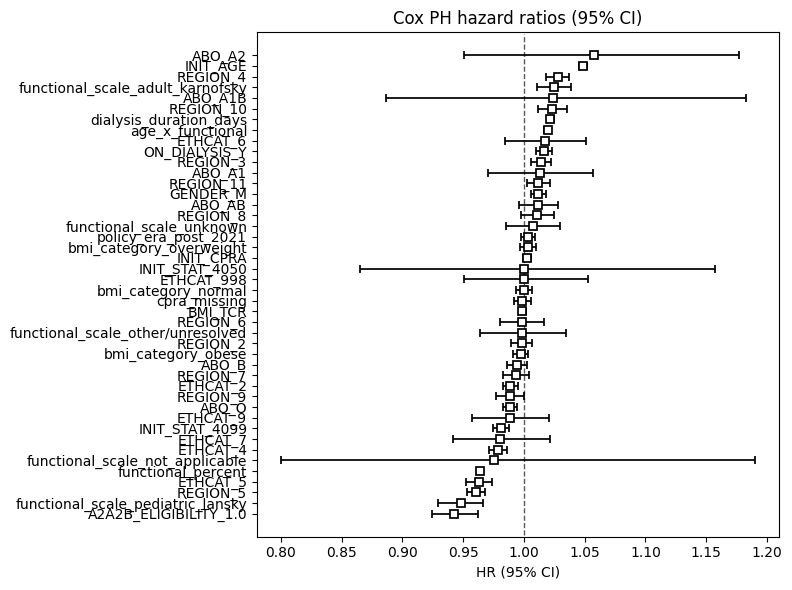

In [32]:
import os, json, joblib
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

os.makedirs("artifacts", exist_ok=True)

plt.figure(figsize=(8, 6))
cph.plot(hazard_ratios=True)
plt.title("Cox PH hazard ratios (95% CI)")
plt.tight_layout()
plt.savefig("artifacts/hazard_ratios.png", dpi=200)
plt.show()

Save metrics, hazard ratios, and model

Saving the headline numbers, the full hazard ratio table, and the fitted model to disk.

In [33]:
metrics = {
    "train_c_index": float(c_index(cph, train_df)),
    "test_c_index": float(c_index(cph, test_df)),
    "penalizer": best_p,
    "n_train": len(train_df),
    "n_test": len(test_df),
}
json.dump(metrics, open("artifacts/metrics.json", "w"), indent=2)
cph.summary.to_csv("artifacts/cox_hazard_ratios.csv")
joblib.dump(cph, "artifacts/cox_model.joblib")
print(metrics)

{'train_c_index': 0.6745411826501149, 'test_c_index': 0.6796329623368939, 'penalizer': 1.0, 'n_train': 395210, 'n_test': 98803}


In [34]:
!zip -rq artifacts.zip artifacts
from google.colab import files
files.download("artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>